In [1]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


### 1. Carga e Información General del Dataset

In [2]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar rutas y cargar datos
sys.path.append("../src")
os.makedirs("../docs/img", exist_ok=True)
df = pd.read_csv("../data/heart_disease.csv")

print("=== Información General ===")
print("Dimensiones:", df.shape)
print("\nValores faltantes por columna:")
print(df.isna().sum()[df.isna().sum() > 0]) # Solo muestra las que tienen nulos (ca y thal)



=== Información General ===
Dimensiones: (303, 14)

Valores faltantes por columna:
ca      4
thal    2
dtype: int64


In [3]:
# Asegurar target binario para las gráficas
df['target_bin'] = (df['target'] > 0).astype(int)

print("\n=== Distribución Demográfica y de Diagnóstico ===")
print("Sexo (1=Hombre, 0=Mujer):\n", df['sex'].value_counts())
print("\nDiagnóstico (1=Enfermo, 0=Sano):\n", df['target_bin'].value_counts())


=== Distribución Demográfica y de Diagnóstico ===
Sexo (1=Hombre, 0=Mujer):
 sex
1    206
0     97
Name: count, dtype: int64

Diagnóstico (1=Enfermo, 0=Sano):
 target_bin
0    164
1    139
Name: count, dtype: int64


### 2. Visualización de Variables Clave

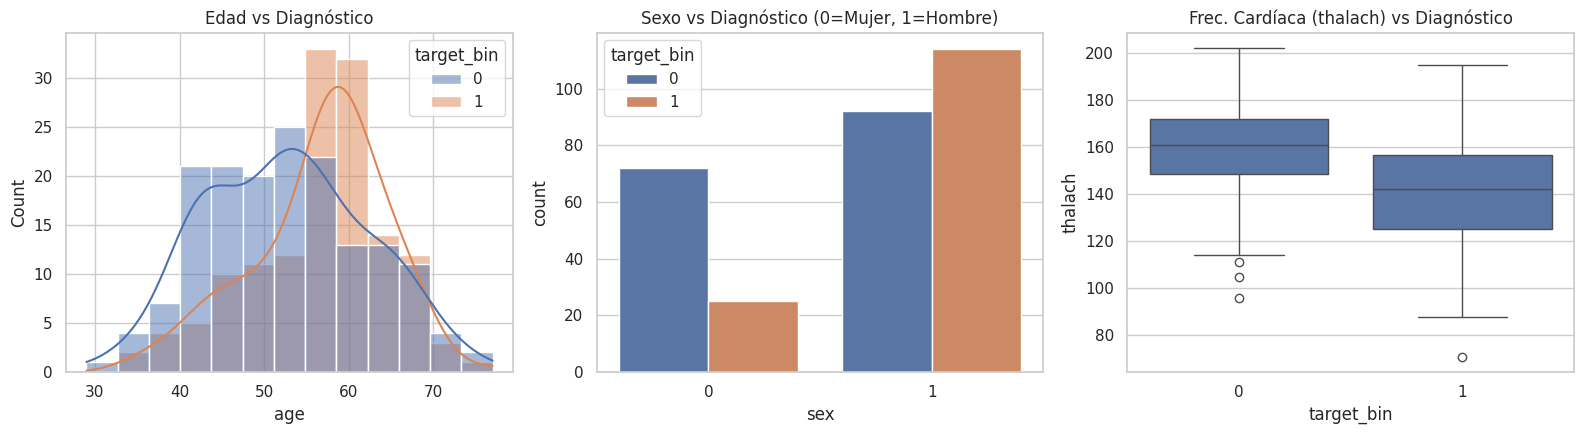

In [4]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
os.makedirs("../docs/img", exist_ok=True)
df = pd.read_csv("../data/heart_disease.csv")

# Asegurar target binario para las gráficas
df['target_bin'] = (df['target'] > 0).astype(int)

# Generar y guardar gráficas exploratorias
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(data=df, x="age", hue="target_bin", kde=True, ax=axes[0])
axes[0].set_title("Edad vs Diagnóstico")

sns.countplot(data=df, x="sex", hue="target_bin", ax=axes[1])
axes[1].set_title("Sexo vs Diagnóstico (0=Mujer, 1=Hombre)")

sns.boxplot(data=df, x="target_bin", y="thalach", ax=axes[2])
axes[2].set_title("Frec. Cardíaca (thalach) vs Diagnóstico")

plt.tight_layout()
plt.savefig("../docs/img/eda_resumen.png", dpi=150)
plt.show()

In [5]:
# Resumen estadístico
print("\n=== Estadísticas Descriptivas ===")
display(df.describe())

# Verificación de limpieza
print(f"\nPacientes restantes tras eliminar nulos: {df.dropna().shape[0]}")


=== Estadísticas Descriptivas ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,target_bin
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000,1.000000



Pacientes restantes tras eliminar nulos: 297
